# Ejercicio Practico

![Logo del instituto](img/ITQ.png)

**Ejercicio practico:** En este ejercicio vamos a aplicar todo lo aprendido de normalización y estandarización,
usando el dataset Iris que es un dataset de flores descargado de kaggle.

**Nombre:** Leticia Verdezoto

**Fecha:** 06-11-2026

**Link:** [Link Repositorio](https://github.com/verdezotoandivel-ctrl/Fundamentos-de-machine-Learning)



In [66]:
#Importacion de librerias
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
import zipfile
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import preprocessing

Importamos pandas para manejar tablas de datos, numpy para los números, load_iris de sklearn para tener el dataset Iris a la mano, zipfile para descomprimir el archivo ZIP que descargamos de Kaggle, seaborn y matplotlib para los gráficos y para poder comparar los datos, preprocessing de sklearn para la normalización y la estandarización para dejar todos los datos en la misma escala, y os para crear la carpeta del dataset y para saber dónde está la llave de Kaggle.

In [82]:
#Configuramos el entorno de descarga
import os
os.environ['KAGGLE_CONFIG_DIR']="C:/Users/Usuario/.kaggle"

In [68]:
#Creamos la carpeta dataset
os.makedirs("dataset", exist_ok=True)

In [69]:
#Descargamos el dataset
!kaggle datasets download -d uciml/iris

Dataset URL: https://www.kaggle.com/datasets/uciml/iris
License(s): CC0-1.0
iris.zip: Skipping, found more recently modified local copy (use --force to force download)


In [70]:
#Descompriminos el archivo
with zipfile.ZipFile("iris.zip", 'r') as zip_ref:
  zip_ref.extractall("dataset")

In [71]:
#Cargamos el conjunto de datos
df = pd.read_csv("dataset/Iris.csv")

In [72]:
#mostramos el conjunto de datos"
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [73]:
#Eliminamos columnas innecesarias en la limpieza de datos como vemos en el␣
#dataframe la columna id no aporta
#nada a nuestro modelo por lo tanto lo eliminamos
if 'Id' in df.columns:
    df=df.drop(columns=["Id"])

In [74]:
#Mostramos los detalles de nuesto dataset
df.info()
#Vrificamos si tenemos datos nulos si lo tenemos lo sumamos
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Aquí vemos los detalles del dataset, cuántas filas tenemos, qué tipo de datos son, y verificamos que no tengamos datos nulos, tenemos 150 filas y 0 nulos, está limpio.

In [75]:
#Separamos los datos de entrada con nuestra variable objetivo
X=df.drop(columns=['Species'])
y=df['Species']

In [76]:
#Exploramos o generamos un analisis exploratorio del conjutno de datos
X.describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


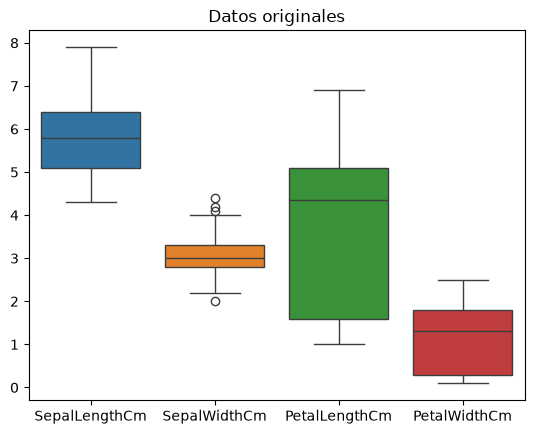

In [77]:
#dibujamso los datos originales
sns.boxplot(data=X)
#Ponemos un titulo a la imagen
plt.title("Datos originales")
plt.show()

En el gráfico se puede observa que las cuatro variables presentan escalas y dispersiones diferentes, ya que SepalLengthCm registra valores entre 4.3 y 7.9 con una mediana aproximada de 5.8, SepalWidthCm presenta la menor variabilidad con valores entre 2.0 y 4.4 y con valores atípicos, PetalLengthCm muestra la mayor dispersión con valores entre 1.0 y 6.9 y con una caja central amplia donde se concentra la mitad de los datos, mientras que PetalWidthCm registra los valores más bajos entre 0.1 y 2.5, lo cual evidencia que las variables no se encuentran en la misma escala existe un desbalance entre ellas.

In [78]:
#Normalizamos el conjunto de datos
normalizer = preprocessing.MinMaxScaler()
X_norm=normalizer.fit_transform(X)
X_norm = pd.DataFrame(X_norm, columns=X.columns)
X_norm.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,0.222222,0.625000,0.067797,0.041667
1,0.166667,0.416667,0.067797,0.041667
2,0.111111,0.500000,0.050847,0.041667
3,0.083333,0.458333,0.084746,0.041667
4,0.194444,0.666667,0.067797,0.041667


In [79]:
X_norm.describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,0.428704,0.439167,0.467571,0.457778
std,0.230018,0.180664,0.299054,0.317984
min,0.000000,0.000000,0.000000,0.000000
25%,0.222222,0.333333,0.101695,0.083333
50%,0.416667,0.416667,0.567797,0.500000
75%,0.583333,0.541667,0.694915,0.708333
max,1.000000,1.000000,1.000000,1.000000


In [80]:
#Estaddarización
standarizer = preprocessing.StandardScaler()
#Estandarizamos los datos
X_std=standarizer.fit_transform(X)
X_std= pd.DataFrame(X_std, columns=X.columns)
X_std.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,-0.900681,1.032057,-1.341272,-1.312977
1,-1.143017,-0.124958,-1.341272,-1.312977
2,-1.385353,0.337848,-1.398138,-1.312977
3,-1.506521,0.106445,-1.284407,-1.312977
4,-1.021849,1.263460,-1.341272,-1.312977


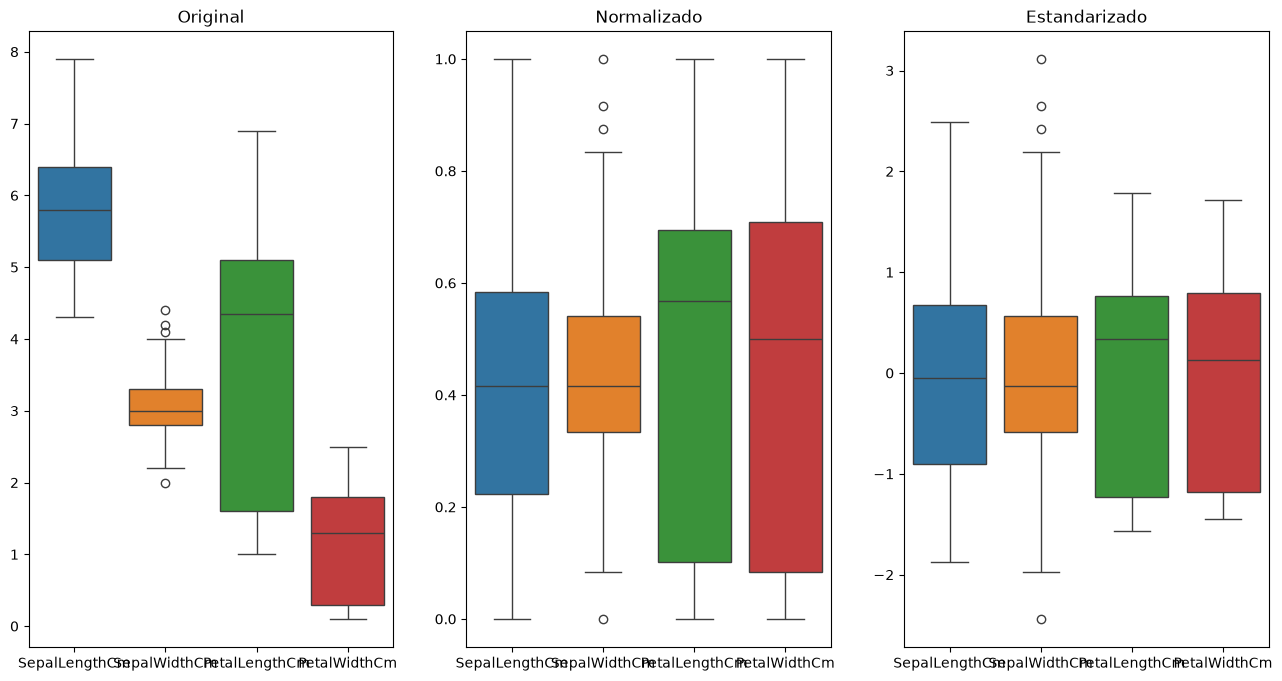

In [81]:
#Comporación visual
plt.figure(figsize=(16,8))
plt.subplot(1,3,1)
sns.boxplot(data=X)
plt.title("Original")
plt.subplot(1,3,2)
sns.boxplot(data=X_norm)
plt.title("Normalizado")
plt.subplot(1,3,3)
sns.boxplot(data=X_std)
plt.title("Estandarizado")
plt.show()

En el gráfico comparativo se observan tres gráficos, en el gráfico Original las cuatro variables presentan escalas y dispersiones diferentes con valores entre 0 y 8, donde SepalLengthCm es la más alta, PetalWidthCm es la más baja y SepalWidthCm presenta valores atípicos, en el gráfico Normalizado todas las variables quedan entre 0 y 1 por MinMaxScaler, lo que permite compararlas y donde la caja central de cada variable muestra donde se concentra la mitad de los datos, y en el gráfico Estandarizado todas las variables quedan centradas en 0 con valores entre -2 y 3 debido a StandardScaler, no se eliminan los valores atípicos, pero sí se deja los datos en una misma escala y el modelo pueda aprender de mejor manera.